# Demo self-attention: giải thích từng bước

Dùng **trọng số đã huấn luyện của GPT-2** (`gpt2`, 124M tham số). Tự viết phép attention, không huấn luyện lại mô hình.

Chạy lần lượt **Bước 1–6**: chuẩn bị → Implementation → kiểm chứng → chọn đầu → vẽ/đọc heatmap → so sánh Transformer/CNN/RNN. Mỗi bước giải thích làm gì và cho ra gì ngay trước ô code. Đo GPU/CPU và kiểm tra bổ sung nằm ở phụ lục.

**Nguồn:** công thức theo [Vaswani et al. (2017), mục 3.2](https://arxiv.org/html/1706.03762v7#S3.SS2); trọng số/tokenizer từ [GPT-2 trên Hugging Face](https://huggingface.co/openai-community/gpt2). [Danh mục nguồn và nguồn hình/số liệu](workflow/THEORY.md) ghi báo cáo GPT-2, mã đối chứng, revision/hash cache và giới hạn tái lập.

## Bước 1 - Chuẩn bị mô hình và câu đầu vào

**Làm gì:** chọn GPU nếu có, nạp GPT-2 đã huấn luyện ở chế độ đánh giá, rồi dùng tokenizer đổi câu mẫu thành token ID; không thêm BOS.

**Kết quả:** in cấu hình máy và danh sách 12 token, lưu `input_ids (1,12)` cho các bước sau. `didn't` được tách thành `didn` và `'t`, nên một token không nhất thiết là một từ.

In [1]:
from pathlib import Path
import json
import platform
import statistics
import time
import torch
import transformers
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from transformers import GPT2Model, GPT2TokenizerFast

torch.manual_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
gpu_name = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "Không có GPU"
cpu_name = platform.processor()
print(f"PyTorch: {torch.__version__} | Transformers: {transformers.__version__}")
print(f"GPU: {gpu_name} | CPU: {cpu_name} | Device: {DEVICE}")

tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2Model.from_pretrained("gpt2", attn_implementation="eager").to(device=DEVICE, dtype=torch.float32).eval()
SENTENCE = "The animal didn't cross the street because it was too tired"
input_ids = tokenizer.encode(SENTENCE, add_special_tokens=False, return_tensors="pt").to(DEVICE)
tokens = [t.replace("Ġ", "") for t in tokenizer.convert_ids_to_tokens(input_ids[0])]
print("Token:", tokens)
assert model.config.n_head == 12 and model.config.n_embd == 768

C:\Users\Legion\Desktop\TÀI LIỆU HỌC\Presenttation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1114 08:29:26.067000 29124 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


PyTorch: 2.9.1+cu128 | Transformers: 5.22.2
GPU: NVIDIA GeForce RTX 5060 Laptop GPU | CPU: AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD | Device: cuda


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   5%|▍         | 7/148 [00:00<00:02, 67.41it/s]

Loading weights:   9%|▉         | 14/148 [00:00<00:02, 44.77it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 491.12it/s]

Token: ['The', 'animal', 'didn', "'t", 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired']


## Bước 2 - Implementation: tự tính self-attention

**Đầu vào:** `get_layer_input` lấy hidden state của lớp đang xét rồi áp `ln_1`, cho `x (T,768)`; `get_qkv_weights` lấy weight/bias QKV đã học của cùng lớp. Với câu mẫu, `T=12` token.

$$A=\operatorname{softmax}(QK^T/\sqrt{d_k}+M),\qquad O=AV.$$

| Bước nhỏ | Làm gì? | Kết quả |
|---|---|---|
| **2.1 - Tạo Q, K, V** | Nhân `x @ w_qkv + b_qkv`, rồi `chunk(3)`. Q là truy vấn, K để đối sánh, V mang thông tin cần tổng hợp. | Ba tensor `(T,768)`, cùng xuất phát từ `x`. |
| **2.2 - Chia 12 đầu** | `view` rồi `transpose` để mỗi đầu xử lý 64 chiều. | Q/K/V đều có shape `(12,T,64)`. |
| **2.3 - Tính điểm** | Nhân `q @ k.transpose(-1,-2)`, chia **√64=8** để giữ độ lớn điểm ổn định. | `scores (12,T,T)`: điểm giữa mỗi Query và mọi Key. |
| **2.4 - Chặn tương lai** | Nếu `causal=True`, dùng `triu(1)` gán `-∞` vào cột tương lai trước softmax; vẫn giữ chính token đang xét. | Hàng `it` chặn các cột `was`, `too`, `tired`. |
| **2.5 - Tính trọng số** | `softmax(scores, dim=-1)` chuẩn hóa theo chiều Key. | `attn (12,T,T)`: mỗi hàng tổng bằng 1, vị trí bị mask bằng 0. |
| **2.6 - Tổng hợp V, ghép đầu** | `attn @ v` lấy tổng có trọng số; transpose và view để nối 12 đầu. | `out (T,768)` và `attn`; đầu ra **chưa qua `c_proj`**. |

Ô code dưới hiện thực đúng sáu bước này, không gọi hàm attention dựng sẵn.

In [2]:
def get_layer_input(model, input_ids, layer: int):
    hidden = model(input_ids, output_hidden_states=True).hidden_states[layer][0]
    return model.h[layer].ln_1(hidden)

def get_qkv_weights(model, layer: int):
    return model.h[layer].attn.c_attn.weight, model.h[layer].attn.c_attn.bias

def self_attention(x, w_qkv, b_qkv, n_head: int = 12, causal: bool = True):
    if x.ndim != 2 or x.shape[0] == 0 or n_head <= 0 or x.shape[1] % n_head:
        raise ValueError("X phải có dạng (T, C), T > 0 và C chia hết cho số đầu dương")
    T, C = x.shape
    if w_qkv.shape != (C, 3 * C) or b_qkv.shape != (3 * C,):
        raise ValueError("Weight/bias QKV không khớp số chiều C")
    d = C // n_head
    # 1. Chiếu tuyến tính rồi tách Q, K, V.
    q, k, v = (x @ w_qkv + b_qkv).chunk(3, dim=-1)
    # 2. Chia thành các đầu: (số đầu, T, d).
    q = q.view(T, n_head, d).transpose(0, 1)
    k = k.view(T, n_head, d).transpose(0, 1)
    v = v.view(T, n_head, d).transpose(0, 1)
    # 3. Tính điểm tương đồng, chia căn kích thước một đầu.
    scores = (q @ k.transpose(-1, -2)) / d**0.5
    # 4. Chặn tương lai, vẫn cho phép nhìn chính token đang xét.
    if causal:
        future = torch.ones(T, T, device=x.device, dtype=torch.bool).triu(1)
        scores = scores.masked_fill(future, float("-inf"))
    # 5. Chuẩn hóa theo Key; 6. Tổng hợp V và ghép các đầu.
    attn = torch.softmax(scores, dim=-1)
    out = (attn @ v).transpose(0, 1).contiguous().view(T, C)
    return out, attn

## Bước 3 - Kiểm chứng với GPT-2 gốc

**Làm gì:** cho hai cách tính cùng câu, trọng số và hidden state **sau `ln_1`**, rồi so ma trận attention ở **cả 12 lớp**.

**Kết quả cần đạt:** sai số lớn nhất <`1e-4`, tổng mỗi hàng bằng 1 và vùng tương lai bằng 0. Ô code in sai số thực; `assert` sẽ dừng nếu phép tính sai.

In [3]:
with torch.inference_mode():
    ref = model(input_ids, output_attentions=True).attentions
    max_diff = 0.0
    for layer in range(model.config.n_layer):
        x = get_layer_input(model, input_ids, layer)
        _, attn = self_attention(x, *get_qkv_weights(model, layer))
        diff = (attn - ref[layer][0]).abs().max().item()
        assert diff < 1e-4, f"Lớp {layer}: sai số {diff:.2e}"
        assert torch.allclose(attn.sum(-1), torch.ones_like(attn.sum(-1)), atol=1e-5)
        assert attn.triu(1).abs().max() == 0
        max_diff = max(max_diff, diff)
print(f"Khớp GPT-2 gốc ở cả 12 lớp; sai số lớn nhất: {max_diff:.2e} < 1e-4")

Khớp GPT-2 gốc ở cả 12 lớp; sai số lớn nhất: 1.76e-06 < 1e-4


## Bước 4 - Chọn đầu attention để minh họa

**Làm gì:** tìm vị trí `it` và `animal`, quét **12 lớp × 12 đầu**, xếp theo attention `it` → `animal` sau mask và in top 3.

**Kết quả:** `best_l`, `best_h`, `best_val` là lớp, đầu và trọng số cao nhất; chỉ số bắt đầu từ 0. Đây là tiêu chí chọn công khai, một đầu được chọn không đại diện toàn mô hình.

In [4]:
def find_token(token_list, word: str) -> int:
    try:
        return token_list.index(word)
    except ValueError:
        raise ValueError(f"Không tìm thấy token '{word}' trong câu: {token_list}") from None

def pick_head(src: int, tgt: int) -> tuple[int, int, float]:
    if not (0 <= src < len(tokens) and 0 <= tgt <= src):
        raise ValueError("Chỉ số token phải hợp lệ; Key không được ở tương lai của Query")
    candidates = []
    with torch.inference_mode():
        for layer in range(model.config.n_layer):
            x = get_layer_input(model, input_ids, layer)
            _, attn = self_attention(x, *get_qkv_weights(model, layer))
            candidates.extend((layer, head, attn[head, src, tgt].item()) for head in range(model.config.n_head))
    candidates.sort(key=lambda item: item[2], reverse=True)
    for rank, (layer, head, value) in enumerate(candidates[:3], 1):
        print(f"Top {rank}: lớp {layer}, đầu {head}, it → animal = {value:.4f} ({value:.2%})")
    return candidates[0]

src, tgt = find_token(tokens, "it"), find_token(tokens, "animal")
assert tgt < src
best_l, best_h, best_val = pick_head(src, tgt)

Top 1: lớp 4, đầu 3, it → animal = 0.8461 (84.61%)
Top 2: lớp 5, đầu 10, it → animal = 0.4135 (41.35%)
Top 3: lớp 6, đầu 0, it → animal = 0.3952 (39.52%)


## Bước 5 - Vẽ và đọc hai heatmap

**Làm gì:** giữ nguyên lớp, đầu và Q/K/V; gọi `self_attention` với `causal=False` rồi `causal=True`, lấy cùng đầu đã chọn và vẽ cạnh nhau, **cùng thang màu 0–1**.

**Đọc kết quả:** hàng là Query, cột là Key. Xem hàng `it`, cột `animal` để biết mức chú ý; sau mask, nửa trên đường chéo phải bằng 0 vì đó là tương lai. Nhận xét ngay dưới hình lấy số từ output thật.

“Trước mask” vẫn là trọng số **sau softmax khi bỏ mask**, không phải scores thô. Đây là phép thử minh họa; GPT-2 được huấn luyện có causal mask.

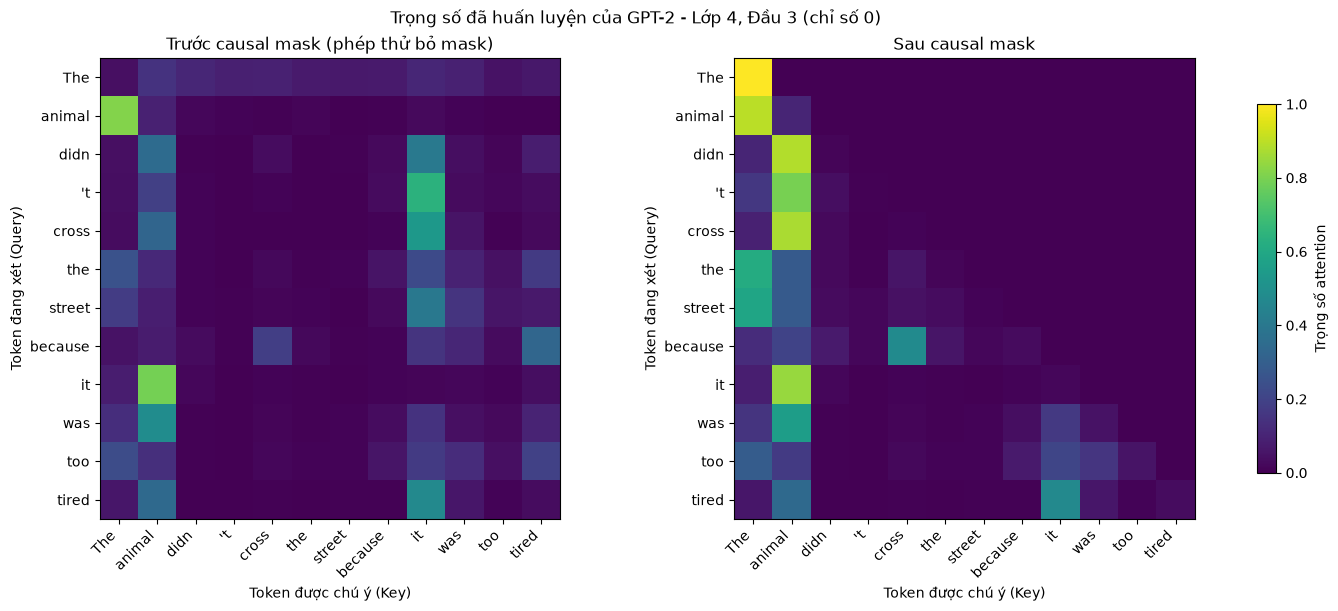

In [5]:
def plot_attention(attn_no_mask, attn_mask, tokens, title, path_prefix) -> None:
    matrices = [matrix.detach().cpu().numpy() for matrix in (attn_no_mask, attn_mask)]
    if any(matrix.shape != (len(tokens), len(tokens)) for matrix in matrices):
        raise ValueError("Ma trận heatmap phải khớp số token trên hai trục")
    panels = ["Trước causal mask (phép thử bỏ mask)", "Sau causal mask"]
    def draw(ax, matrix, panel):
        im = ax.imshow(matrix, cmap="viridis", vmin=0, vmax=1)
        ax.set(xticks=range(len(tokens)), yticks=range(len(tokens)), xlabel="Token được chú ý (Key)", ylabel="Token đang xét (Query)", title=panel)
        ax.set_xticklabels(tokens, rotation=45, ha="right")
        ax.set_yticklabels(tokens)
        return im
    prefix = Path(path_prefix)
    prefix.parent.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
    for ax, matrix, panel in zip(axes, matrices, panels):
        im = draw(ax, matrix, panel)
    fig.colorbar(im, ax=list(axes), shrink=.8, label="Trọng số attention")
    fig.suptitle(title)
    fig.savefig(f"{prefix}_compare.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    for matrix, panel, suffix in zip(matrices, panels, ("no_mask", "causal_mask")):
        fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
        im = draw(ax, matrix, panel)
        fig.suptitle(title)
        fig.colorbar(im, ax=ax, label="Trọng số attention")
        fig.savefig(f"{prefix}_{suffix}.png", dpi=200, bbox_inches="tight")
        plt.close(fig)

with torch.inference_mode():
    x = get_layer_input(model, input_ids, best_l)
    w, b = get_qkv_weights(model, best_l)
    _, no_mask = self_attention(x, w, b, causal=False)
    _, masked = self_attention(x, w, b, causal=True)
assert masked.triu(1).abs().max() == 0 and no_mask.triu(1).abs().max() > 0
head_no_mask, head_mask = no_mask[best_h], masked[best_h]
plot_attention(head_no_mask, head_mask, tokens, f"Trọng số đã huấn luyện của GPT-2 - Lớp {best_l}, Đầu {best_h} (chỉ số 0)", "figures/heatmap")

In [6]:
before = head_no_mask[src, tgt].item()
after = head_mask[src, tgt].item()
first_token_mean = head_mask[1:, 0].mean().item()
display(Markdown(f"**Nhìn hình:** ở lớp {best_l}, đầu {best_h}, `it → animal` là **{before:.2%} trước mask**, **{after:.2%} sau mask**. Sau mask, vùng tương lai bằng **0**. Attention trung bình về `{tokens[0]}` của các token phía sau là **{first_token_mean:.2%}**; đây chỉ là quan sát tại đầu này, không chứng minh toàn bộ cách GPT-2 hiểu câu."))

**Nhìn hình:** ở lớp 4, đầu 3, `it → animal` là **79.30% trước mask**, **84.61% sau mask**. Sau mask, vùng tương lai bằng **0**. Attention trung bình về `The` của các token phía sau là **28.76%**; đây chỉ là quan sát tại đầu này, không chứng minh toàn bộ cách GPT-2 hiểu câu.

## Bước 6 - So sánh Transformer, CNN và RNN

**Làm gì:** đối chiếu ba cách xử lý chuỗi trong bảng. **Kết quả:** nêu được ưu điểm và hạn chế của attention từ cơ chế tính toán.

| Điểm so sánh | Transformer | CNN trên chuỗi | RNN |
|---|---|---|---|
| Cách xử lý | Attention giữa các vị trí | Bộ lọc trên cửa sổ cục bộ | Trạng thái truyền từng bước |
| Song song khi xử lý chuỗi đã có | Tốt qua nhân ma trận | Tốt giữa các vị trí | Bị ràng buộc theo bước thời gian |
| Quan hệ xa | Kết nối trực tiếp qua attention | Cần tăng vùng nhìn bằng nhiều lớp/dilation | Qua nhiều trạng thái; LSTM/GRU hỗ trợ ghi nhớ |
| Hạn chế chính | Attention dày đặc tốn bộ nhớ O(N²) | Một lớp có vùng nhìn giới hạn | Khó song song theo thời gian |

**Ưu điểm attention:** tổng hợp ngữ cảnh linh hoạt, nối vị trí xa và tận dụng nhân ma trận song song. **Hạn chế:** ma trận N×N lớn; cần thông tin vị trí; heatmap chỉ cho thấy một phần hoạt động. GPT-2 sinh văn bản vẫn tuần tự theo token.

Đây là so sánh **lý thuyết**, không phải kết quả huấn luyện/benchmark ba mô hình trên cùng dữ liệu. Nguồn: [Vaswani et al., mục 4](https://arxiv.org/html/1706.03762v7#S4), [Gehring et al.](https://arxiv.org/abs/1705.03122).

## Phụ lục - Đo chi phí GPU/CPU

Phần này không cần trình bày hết khi demo. Dùng tensor/weight ngẫu nhiên seed 42, 12 đầu ×64 chiều; N=128–2048 **không phải** chạy GPT-2 ở context 2048.

Warm-up 3, lấy trung vị **20 lần trên mỗi thiết bị**, inference mode, đồng bộ CUDA trước/sau bấm giờ. GPU là đỉnh tensor PyTorch **gồm cả mô hình đang nạp**; CPU là dung lượng **ma trận attention thực trả về** (cùng shape/dtype với scores), không phải peak RAM. Đơn vị MiB; không dùng hai đường này để so mức tiết kiệm bộ nhớ giữa thiết bị.

**Các bước đo:** (1) tạo tensor ngẫu nhiên cho từng N → (2) làm nóng và đo thời gian → (3) ghi bộ nhớ, gặp OOM thì đo tiếp → (4) vẽ bảng/biểu đồ và nhận xét từ số thật.

In [7]:
def benchmark(lengths: list[int], device: str, n_rep: int = 20) -> list[dict]:
    if n_rep <= 0 or any(length <= 0 for length in lengths):
        raise ValueError("Độ dài và số lần đo phải dương")
    results = []
    dev = torch.device(device)
    for seq_len in lengths:
        x = w_qkv = b_qkv = out = attn = None
        try:
            # Cả cấp phát input/weight lẫn phép attention đều được bắt OOM.
            with torch.inference_mode():
                gen = torch.Generator(device=dev).manual_seed(42)
                w_qkv = torch.randn(768, 2304, generator=gen, device=dev)
                b_qkv = torch.randn(2304, generator=gen, device=dev)
                x = torch.randn(seq_len, 768, generator=gen, device=dev)
                for _ in range(3):
                    out, attn = self_attention(x, w_qkv, b_qkv)
                    out = attn = None
                if dev.type == "cuda":
                    torch.cuda.synchronize()
                    torch.cuda.reset_peak_memory_stats()
                out, attn = self_attention(x, w_qkv, b_qkv)
                if dev.type == "cuda":
                    torch.cuda.synchronize()
                    mem_mb = torch.cuda.max_memory_allocated() / 2**20
                else:
                    mem_mb = attn.nelement() * attn.element_size() / 2**20
                out = attn = None
                times = []
                for _ in range(n_rep):
                    if dev.type == "cuda":
                        torch.cuda.synchronize()
                    start = time.perf_counter()
                    out, attn = self_attention(x, w_qkv, b_qkv)
                    if dev.type == "cuda":
                        torch.cuda.synchronize()
                    times.append((time.perf_counter() - start) * 1000)
                    out = attn = None
                results.append({"len": seq_len, "ms": statistics.median(times), "mem_mb": mem_mb})
        except torch.OutOfMemoryError:
            results.append({"len": seq_len, "ms": None, "mem_mb": None})
        finally:
            x = w_qkv = b_qkv = out = attn = None
        if dev.type == "cuda" and results[-1]["ms"] is None:
            torch.cuda.empty_cache()
    return results

r_test = benchmark([16, 32], "cpu", n_rep=2)
assert all(row["ms"] > 0 for row in r_test)
assert abs(r_test[1]["mem_mb"] / r_test[0]["mem_mb"] - 4) < 1e-6

N | GPU ms | CPU ms | GPU đỉnh MiB | CPU ma trận MiB
128 | 0.31 | 0.99 | 496.79 | 0.75
256 | 0.29 | 2.01 | 502.71 | 3.00
512 | 0.51 | 5.31 | 526.90 | 12.00
1024 | 2.36 | 25.49 | 607.15 | 48.00
2048 | 8.46 | 88.35 | 916.15 | 192.00


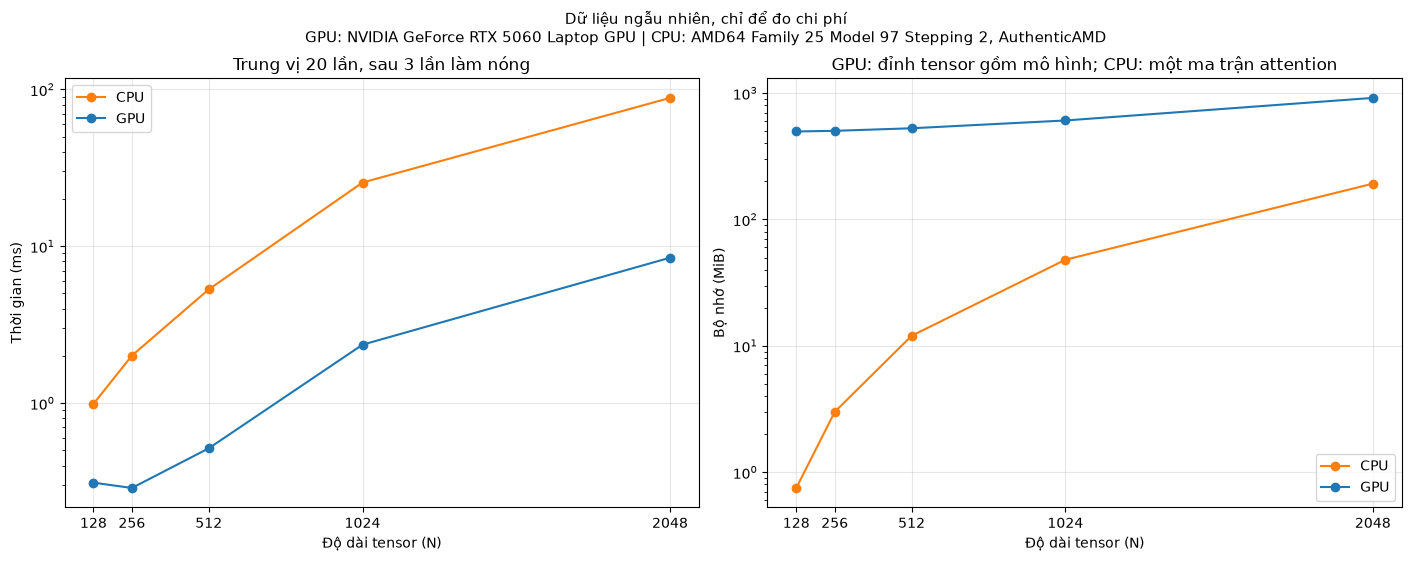

In [8]:
LENGTHS = [128, 256, 512, 1024, 2048]
res_cpu = benchmark(LENGTHS, "cpu")
res_gpu = benchmark(LENGTHS, "cuda") if torch.cuda.is_available() else None
if res_gpu is None:
    print("Không có GPU, chỉ đo CPU")
print("N | GPU ms | CPU ms | GPU đỉnh MiB | CPU ma trận MiB")
for i, length in enumerate(LENGTHS):
    g = res_gpu[i] if res_gpu else {"ms": "N/A", "mem_mb": "N/A"}
    c = res_cpu[i]
    values = [g["ms"], c["ms"], g["mem_mb"], c["mem_mb"]]
    formatted = ["OOM" if value is None else (f"{value:.2f}" if isinstance(value, (int, float)) else value) for value in values]
    print(str(length) + " | " + " | ".join(formatted))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")
for rows, label, color in [(res_cpu, "CPU", "tab:orange"), (res_gpu, "GPU", "tab:blue")]:
    if rows is None:
        continue
    for ax, metric in zip(axes, ["ms", "mem_mb"]):
        values = [float("nan") if row[metric] is None else row[metric] for row in rows]
        ax.plot(LENGTHS, values, marker="o", label=label, color=color)
        failed = [str(row["len"]) for row in rows if row[metric] is None]
        if failed:
            ax.text(.03, .94 if label == "CPU" else .84, f"{label} OOM: " + ", ".join(failed), transform=ax.transAxes, color=color)
for ax in axes:
    ax.set(yscale="log", xlabel="Độ dài tensor (N)", xticks=LENGTHS)
    ax.grid(alpha=.3)
    ax.legend()
axes[0].set(ylabel="Thời gian (ms)", title="Trung vị 20 lần, sau 3 lần làm nóng")
axes[1].set(ylabel="Bộ nhớ (MiB)", title="GPU: đỉnh tensor gồm mô hình; CPU: một ma trận attention")
fig.suptitle(f"Dữ liệu ngẫu nhiên, chỉ để đo chi phí\nGPU: {gpu_name} | CPU: {cpu_name}", fontsize=11)
fig.savefig("figures/cost_gpu_cpu.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

In [9]:
valid_cpu = [row for row in res_cpu if row["mem_mb"] is not None]
if len(valid_cpu) >= 2:
    first, last = valid_cpu[0], valid_cpu[-1]
    display(Markdown(f"**Chi phí:** ma trận attention tăng từ **{first['mem_mb']:.2f} MiB** (N={first['len']}) lên **{last['mem_mb']:.2f} MiB** (N={last['len']}). Kích thước N×N tăng 4 lần khi N gấp đôi."))
pairs = [(c, g) for c, g in zip(res_cpu, res_gpu or []) if c["ms"] is not None and g["ms"] is not None]
if pairs:
    c, g = pairs[-1]
    display(Markdown(f"Ở N={c['len']}, CPU **{c['ms']:.2f} ms**, GPU **{g['ms']:.2f} ms** → GPU nhanh hơn **{c['ms']/g['ms']:.2f} lần trong lượt này**. Đây là chi phí hàm attention, không phải độ trễ toàn bộ GPT-2."))
else:
    display(Markdown("Không có cặp số đo GPU/CPU hợp lệ để tính tỷ lệ (thiếu GPU hoặc OOM)."))

demo_results = {
    "environment": {"gpu": gpu_name, "cpu": cpu_name, "torch": torch.__version__, "transformers": transformers.__version__},
    "method": {"seed": 42, "warmup": 3, "repetitions": 20, "memory_unit": "MiB", "cpu_memory": "returned_attention_matrix", "gpu_memory": "total_peak_allocated_including_model"},
    "verification": {"max_diff": max_diff, "layers": model.config.n_layer},
    "heatmap": {"layer": best_l, "head": best_h, "before": before, "after": after, "first_token_mean": first_token_mean},
    "cpu": res_cpu, "gpu": res_gpu,
}
Path("figures/demo_results.json").write_text(json.dumps(demo_results, ensure_ascii=False, indent=2), encoding="utf-8")

**Chi phí:** ma trận attention tăng từ **0.75 MiB** (N=128) lên **192.00 MiB** (N=2048). Kích thước N×N tăng 4 lần khi N gấp đôi.

Ở N=2048, CPU **88.35 ms**, GPU **8.46 ms** → GPU nhanh hơn **10.45 lần trong lượt này**. Đây là chi phí hàm attention, không phải độ trễ toàn bộ GPT-2.

1568

### Kiểm tra bổ sung

Assert ví dụ số nhỏ và mô phỏng OOM ở cấp phát/attention; không gây đầy bộ nhớ thật. Các kiểm tra này chạy cùng Run All, không cần giải thích hết khi thuyết trình.

In [10]:
from unittest.mock import patch

# Ví dụ tính tay: X là ma trận đơn vị, các phép chiếu cũng là đơn vị.
test_x = torch.eye(2)
test_w = torch.cat([torch.eye(2)] * 3, dim=1)
test_out, test_attn = self_attention(test_x, test_w, torch.zeros(6), n_head=1)
p = torch.exp(torch.tensor(1 / 2**0.5))
expected = torch.tensor([[1., 0.], [1 / (1 + p), p / (1 + p)]])
assert torch.allclose(test_attn[0], expected, atol=1e-6) and torch.allclose(test_out, expected, atol=1e-6)

original_randn = torch.randn
for fail_at in (1, 2, 3):
    allocation_calls = [0]
    def fail_once(*args, **kwargs):
        allocation_calls[0] += 1
        if allocation_calls[0] == fail_at:
            raise torch.OutOfMemoryError("Mô phỏng lỗi cấp phát")
        return original_randn(*args, **kwargs)
    with patch("torch.randn", side_effect=fail_once):
        rows = benchmark([2, 3], "cpu", n_rep=1)
    assert rows[0]["ms"] is None and rows[1]["ms"] > 0

def attention_oom(*args, **kwargs):
    raise torch.OutOfMemoryError("Mô phỏng lỗi trong attention")
with patch.dict(benchmark.__globals__, self_attention=attention_oom):
    assert all(row["ms"] is None for row in benchmark([2, 3], "cpu", n_rep=1))
print("Đạt: ví dụ số tính tay, OOM ở weight/bias/input và attention; đo tiếp sau OOM.")

Đạt: ví dụ số tính tay, OOM ở weight/bias/input và attention; đo tiếp sau OOM.


### Cách chạy

Cài theo README, chọn kernel `.venv` trong VS Code → **Restart** → **Run All**. Lần đầu cần mạng tải GPT-2; dùng `HF_HUB_OFFLINE=1` khi cache đã có. PNG và `figures/demo_results.json` được cập nhật từ lượt chạy thật. Repo chỉ giữ code, tài liệu kỹ thuật và output do notebook tạo; các tệp trình chiếu đã được bỏ.